<a href="https://colab.research.google.com/github/paulacasas/AplicacionWebConBlazor/blob/main/ProyectoFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ================================
# PROYECTO FINAL: Mineria de datos
# ANALISIS DE RECAUDO PELICULAS
# ================================

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup

print("Inicio correctamente")


Inicio correctamente


In [ ]:

# PASO 1: comprobar la conexión con Box Office Mojo
# Consultar la tabla a nivel mundial de peliculas del año 2024

from io import StringIO

url_prueba = "https://www.boxofficemojo.com/year/world/2024/"

# Identificamos nuestra solicitud como un navegador
encabezados = {
    "User-Agent": "Mozilla/5.0"
}

respuesta = requests.get(
    url_prueba,
    headers=encabezados,
    timeout=30
)

print("Código de respuesta:", respuesta.status_code)

# Leemos las tablas HTML de la página usando Pandas
tablas = pd.read_html(StringIO(respuesta.text))

print("Cantidad de tablas encontradas:", len(tablas))

# Mostramos las columnas de la primera tabla
print("\nColumnas encontradas:")
print(tablas[0].columns.tolist())

# Mostramos las primeras cinco peliculas
print("\nPrimeros cinco registros:")
display(tablas[0].head())


Código de respuesta: 200
Cantidad de tablas encontradas: 1

Columnas encontradas:
['Rank', 'Release Group', 'Worldwide', 'Domestic', '%', 'International', '%.1']

Primeros cinco registros:


,Rank,Release Group,Worldwide,Domestic,%,International,%.1
0,1,Inside Out 2,"$1,698,863,816","$652,980,194",38.4%,"$1,045,883,622",61.6%
1,2,Deadpool & Wolverine,"$1,338,073,645","$636,745,858",47.6%,"$701,327,787",52.4%
2,3,Moana 2,"$1,059,242,164","$460,405,297",43.5%,"$598,836,867",56.5%
3,4,Despicable Me 4,"$972,021,410","$361,004,205",37.1%,"$611,017,205",62.9%
4,5,Wicked,"$764,212,312","$474,983,975",62.2%,"$289,228,337",37.8%


In [ ]:

# FASE I: WEB SCRAPING AUTOMATIZADO
# Extracción de peliculas internacionales entre 2015 y 2024

import time
from io import StringIO

# Definimos los años que vamos a consultar
lista_anios = range(2015, 2025)

# Lista donde guardaremos los fragmentos extraídos
fragmentos_peliculas = []

# Encabezado para acceder a las páginas
encabezados = {
    "User-Agent": "Mozilla/5.0"
}

# Recorremos cada año automáticamente
for anio in lista_anios:

    # Construimos una URL dinamica para cada año
    url = f"https://www.boxofficemojo.com/year/world/{anio}/"

    print(f"Consultando el año {anio}...")

    try:
        # Solicitamos la página web
        respuesta = requests.get(
            url,
            headers=encabezados,
            timeout=30
        )

        respuesta.raise_for_status()

        # Extraemos las tablas HTML con Pandas
        tablas = pd.read_html(StringIO(respuesta.text))

        datos_anio = tablas[0].copy() # Tomamos la primera tabla de la página

        datos_anio["Año"] = anio # Agregamos el año a cada registro

        # Guardamos el fragmento en nuestra lista
        fragmentos_peliculas.append(datos_anio)

        print(f"  Se extrajeron {len(datos_anio)} películas.")

        # Pequeña pausa entre consultas
        time.sleep(1)

    except Exception as error:
        print(f"  No se pudo consultar {anio}: {error}")

# Comprobamos cuántos años se pudieron consultar
print("\nAños consultados correctamente:", len(fragmentos_peliculas))
print("Total de fragmentos extraídos:", len(fragmentos_peliculas))


Consultando el año 2015...
  Se extrajeron 200 películas.
Consultando el año 2016...
  Se extrajeron 200 películas.
Consultando el año 2017...
  Se extrajeron 200 películas.
Consultando el año 2018...
  Se extrajeron 200 películas.
Consultando el año 2019...
  Se extrajeron 200 películas.
Consultando el año 2020...
  Se extrajeron 200 películas.
Consultando el año 2021...
  Se extrajeron 200 películas.
Consultando el año 2022...
  Se extrajeron 200 películas.
Consultando el año 2023...
  Se extrajeron 200 películas.
Consultando el año 2024...
  Se extrajeron 200 películas.

Años consultados correctamente: 10
Total de fragmentos extraídos: 10


In [ ]:

# FASE II: CONSOLIDACIÓN Y REVISIÓN DE LOS DATOS

# Unir los datos de todos los años en una sola tabla
peliculas = pd.concat(fragmentos_peliculas, ignore_index=True)

print("DATOS CONSOLIDADOS")
print("Total de registros:", len(peliculas))
print("Cantidad de columnas:", len(peliculas.columns))

# Mostrar las primeras 5 películas
print("\nPRIMERAS 5 PELÍCULAS:")
display(peliculas.head())

# Revisar los nombres de las columnas
print("\nCOLUMNAS:")
print(peliculas.columns.tolist())

# Identificar registros duplicados
duplicados = peliculas.duplicated(
    subset=["Año", "Release Group"]
).sum()

print("\nREGISTROS DUPLICADOS:", duplicados)

# Eliminar registros duplicados
peliculas = peliculas.drop_duplicates(
    subset=["Año", "Release Group"]
)

print("Registros después de eliminar duplicados:", len(peliculas))

# Identificar datos faltantes
print("\nDATOS FALTANTES POR COLUMNA:")
print(peliculas.isna().sum())


DATOS CONSOLIDADOS
Total de registros: 2000
Cantidad de columnas: 8

PRIMERAS 5 PELÍCULAS:


,Rank,Release Group,Worldwide,Domestic,%,International,%.1,Año
0,1,Star Wars: Episode VII - The Force Awakens,"$2,068,223,624","$936,662,225",45.3%,"$1,131,561,399",54.7%,2015
1,2,Jurassic World,"$1,670,400,637","$652,270,625",39.0%,"$1,018,130,012",61.0%,2015
2,3,Furious 7,"$1,515,047,671","$353,007,020",23.3%,"$1,162,040,651",76.7%,2015
3,4,Avengers: Age of Ultron,"$1,402,805,868","$459,005,868",32.7%,"$943,800,000",67.3%,2015
4,5,Minions,"$1,159,398,397","$336,045,770",29.0%,"$823,352,627",71.0%,2015



COLUMNAS:
['Rank', 'Release Group', 'Worldwide', 'Domestic', '%', 'International', '%.1', 'Año']

REGISTROS DUPLICADOS: 1
Registros después de eliminar duplicados: 1999

DATOS FALTANTES POR COLUMNA:
Rank             0
Release Group    0
Worldwide        0
Domestic         0
%                0
International    0
%.1              0
Año              0
dtype: int64


In [ ]:

# CONVERSIÓN DE TEXTO A DATOS NUMÉRICOS

# Convertir las columnas de dinero
columnas_dinero = ["Worldwide", "Domestic", "International"]

for columna in columnas_dinero:
    peliculas[columna] = (
        peliculas[columna]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
    )
    peliculas[columna] = pd.to_numeric(
        peliculas[columna], errors="coerce"
    )

# Convertir las columnas de porcentajes
columnas_porcentaje = ["%", "%.1"]

for columna in columnas_porcentaje:
    peliculas[columna] = (
        peliculas[columna]
        .astype(str)
        .str.replace("%", "", regex=False)
    )
    peliculas[columna] = pd.to_numeric(
        peliculas[columna], errors="coerce"
    )

# Convertir el ranking y el año a números enteros
peliculas["Rank"] = pd.to_numeric(
    peliculas["Rank"], errors="coerce"
).astype("Int64")

peliculas["Año"] = pd.to_numeric(
    peliculas["Año"], errors="coerce"
).astype("Int64")

# Comprobar los tipos de datos
print("TIPOS DE DATOS DESPUÉS DE LA CONVERSIÓN:")
print(peliculas.dtypes)

print("\nPRIMERAS 5 FILAS CON LOS DATOS CONVERTIDOS:")
display(peliculas.head())

print("\nDATOS FALTANTES DESPUÉS DE LA CONVERSIÓN:")
print(peliculas.isna().sum())


TIPOS DE DATOS DESPUÉS DE LA CONVERSIÓN:
Rank               Int64
Release Group     object
Worldwide          int64
Domestic         float64
%                float64
International    float64
%.1              float64
Año                Int64
dtype: object

PRIMERAS 5 FILAS CON LOS DATOS CONVERTIDOS:


,Rank,Release Group,Worldwide,Domestic,%,International,%.1,Año
0,1,Star Wars: Episode VII - The Force Awakens,2068223624,936662225.0,45.3,1.131561e+09,54.7,2015
1,2,Jurassic World,1670400637,652270625.0,39.0,1.018130e+09,61.0,2015
2,3,Furious 7,1515047671,353007020.0,23.3,1.162041e+09,76.7,2015
3,4,Avengers: Age of Ultron,1402805868,459005868.0,32.7,9.438000e+08,67.3,2015
4,5,Minions,1159398397,336045770.0,29.0,8.233526e+08,71.0,2015



DATOS FALTANTES DESPUÉS DE LA CONVERSIÓN:
Rank               0
Release Group      0
Worldwide          0
Domestic         623
%                648
International     12
%.1               15
Año                0
dtype: int64


In [ ]:

# REVISIÓN DE LOS VALORES FALTANTES

# Mostrar películas que no tienen recaudación nacional
print("PELÍCULAS SIN DATO DOMESTIC:")
display(
    peliculas[peliculas["Domestic"].isna()][
        ["Año", "Release Group", "Worldwide",
         "Domestic", "International"]
    ].head(10)
)

# Mostrar películas sin recaudación internacional
print("\nPELÍCULAS SIN DATO INTERNATIONAL:")
display(
    peliculas[peliculas["International"].isna()][
        ["Año", "Release Group", "Worldwide",
         "Domestic", "International"]
    ].head(10)
)

# Calcular el porcentaje de datos faltantes
print("\nPORCENTAJE DE DATOS FALTANTES:")
print((peliculas.isna().mean() * 100).round(2))


PELÍCULAS SIN DATO DOMESTIC:


,Año,Release Group,Worldwide,Domestic,International
40,2015,Jian Bing Man,186683536,NaN,186683536.0
45,2015,From Vegas to Macau II,163877532,NaN,163877532.0
50,2015,Monkey King: Hero Is Back,153262397,NaN,153262397.0
69,2015,Chronicles of the Ghostly Tribe,106380000,NaN,106380000.0
88,2015,Our Times,83867493,NaN,83867493.0
89,2015,Suck Me Shakespeer 2,83027924,NaN,83027924.0
91,2015,Wolf Warrior,81411331,NaN,81411331.0
95,2015,The Left Ear,78015473,NaN,78015473.0
96,2015,Tiny Times 4.0,77750000,NaN,77750000.0
103,2015,A Violent Prosecutor,66736633,NaN,66736633.0



PELÍCULAS SIN DATO INTERNATIONAL:


,Año,Release Group,Worldwide,Domestic,International
392,2016,Kevin Hart: What Now?,23591043,23591043.0,NaN
916,2019,Uncut Gems,50023780,50023780.0,NaN
921,2019,Isn't It Romantic,48791187,48791187.0,NaN
990,2019,Shaft,21360215,21360215.0,NaN
1092,2020,News of the World,12668325,12668325.0,NaN
1105,2020,Impractical Jokers: The Movie,10691091,10691091.0,NaN
1191,2020,The SpongeBob Movie: Sponge on the Run,4810790,4810790.0,NaN
1299,2021,American Underdog,26514814,26514814.0,NaN
1344,2021,Christmas with the Chosen: The Messengers,13728000,13728000.0,NaN
1546,2022,Glass Onion,13280000,13280000.0,NaN



PORCENTAJE DE DATOS FALTANTES:
Rank              0.00
Release Group     0.00
Worldwide         0.00
Domestic         31.17
%                32.42
International     0.60
%.1               0.75
Año               0.00
dtype: float64


In [ ]:

# TRATAMIENTO DE DATOS FALTANTES

# Contar los valores faltantes antes de corregirlos
faltantes_antes = peliculas.isna().sum()

# Calcular Domestic cuando falta, usando Worldwide - International
peliculas["Domestic"] = peliculas["Domestic"].fillna(
    peliculas["Worldwide"] - peliculas["International"]
)

# Calcular International cuando falta, usando Worldwide - Domestic
peliculas["International"] = peliculas["International"].fillna(
    peliculas["Worldwide"] - peliculas["Domestic"]
)

# Calcular nuevamente los porcentajes
peliculas["%"] = (
    peliculas["Domestic"] / peliculas["Worldwide"] * 100
).round(1)

peliculas["%.1"] = (
    peliculas["International"] / peliculas["Worldwide"] * 100
).round(1)

# Mostrar los resultados
print("VALORES FALTANTES ANTES DEL TRATAMIENTO:")
print(faltantes_antes)

print("\nVALORES FALTANTES DESPUÉS DEL TRATAMIENTO:")
print(peliculas.isna().sum())

print("\nTOTAL DE PELÍCULAS CONSERVADAS:", len(peliculas))

print("\nPRIMERAS 5 FILAS:")
display(peliculas.head())


VALORES FALTANTES ANTES DEL TRATAMIENTO:
Rank               0
Release Group      0
Worldwide          0
Domestic         623
%                648
International     12
%.1               15
Año                0
dtype: int64

VALORES FALTANTES DESPUÉS DEL TRATAMIENTO:
Rank             0
Release Group    0
Worldwide        0
Domestic         0
%                0
International    0
%.1              0
Año              0
dtype: int64

TOTAL DE PELÍCULAS CONSERVADAS: 1999

PRIMERAS 5 FILAS:


,Rank,Release Group,Worldwide,Domestic,%,International,%.1,Año
0,1,Star Wars: Episode VII - The Force Awakens,2068223624,936662225.0,45.3,1.131561e+09,54.7,2015
1,2,Jurassic World,1670400637,652270625.0,39.0,1.018130e+09,61.0,2015
2,3,Furious 7,1515047671,353007020.0,23.3,1.162041e+09,76.7,2015
3,4,Avengers: Age of Ultron,1402805868,459005868.0,32.7,9.438000e+08,67.3,2015
4,5,Minions,1159398397,336045770.0,29.0,8.233526e+08,71.0,2015


In [ ]:

# FILTROS AVANZADOS CON OPERADORES LÓGICOS

peliculas_filtradas = peliculas[
    (peliculas["Año"] >= 2018) &
    (peliculas["Año"] <= 2024) &
    (
        (peliculas["Worldwide"] >= 100000000) |
        (peliculas["International"] >= 50000000)
    )
].copy()

# Mostrar resultados
print("RESULTADOS DE LOS FILTROS AVANZADOS")
print("Total de películas originales:", len(peliculas))
print("Películas que cumplen los filtros:", len(peliculas_filtradas))

print("\nPRIMERAS 10 PELÍCULAS FILTRADAS:")
display(
    peliculas_filtradas[
        ["Año", "Release Group", "Worldwide",
         "Domestic", "International"]
    ].head(10)
)

# Resumen por año
print("\nCANTIDAD DE PELÍCULAS POR AÑO:")
print(peliculas_filtradas["Año"].value_counts().sort_index())


RESULTADOS DE LOS FILTROS AVANZADOS
Total de películas originales: 1999
Películas que cumplen los filtros: 459

PRIMERAS 10 PELÍCULAS FILTRADAS:


,Año,Release Group,Worldwide,Domestic,International
600,2018,Avengers: Infinity War,2048359754,678815482.0,1.369544e+09
601,2018,Black Panther,1346913161,700059566.0,6.468536e+08
602,2018,Jurassic World: Fallen Kingdom,1308467944,417719760.0,8.907482e+08
603,2018,Incredibles 2,1242805359,608581744.0,6.342236e+08
604,2018,Aquaman,1151961807,335061807.0,8.169000e+08
605,2018,Bohemian Rhapsody,903655259,216428042.0,6.872272e+08
606,2018,Venom,856085151,213515506.0,6.425696e+08
607,2018,Mission: Impossible - Fallout,791115104,220159104.0,5.709560e+08
608,2018,Deadpool 2,734546611,318491426.0,4.160552e+08
609,2018,Fantastic Beasts: The Crimes of Grindelwald,655755901,159555901.0,4.962000e+08



CANTIDAD DE PELÍCULAS POR AÑO:
Año
2018    93
2019    98
2020    28
2021    56
2022    49
2023    77
2024    58
Name: count, dtype: Int64


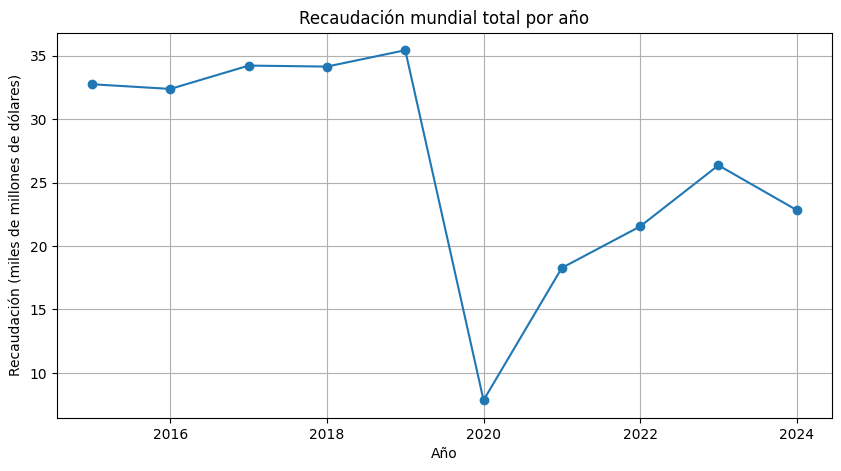

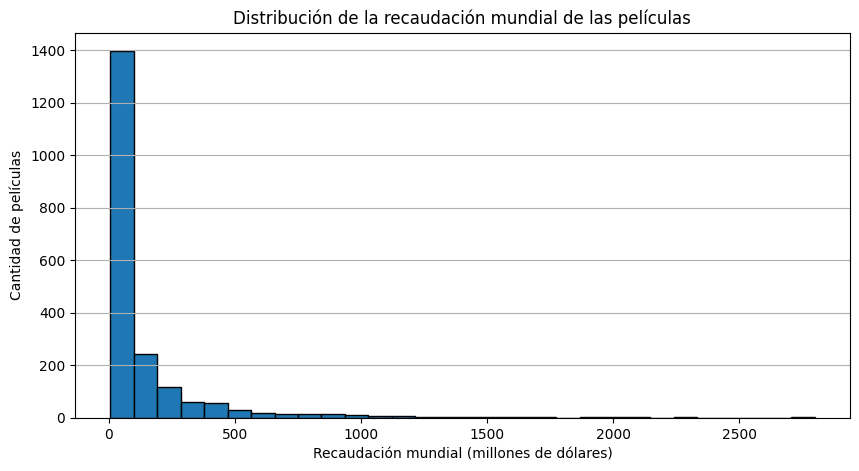

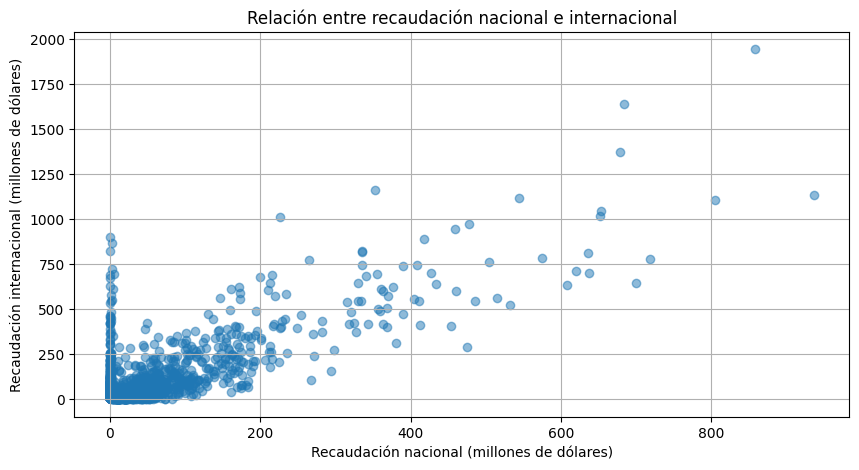

In [ ]:

# FASE III: ANÁLISIS EXPLORATORIO DE DATOS (EDA)

# GRÁFICA 1: Recaudación mundial total por año

recaudacion_anual = peliculas.groupby("Año")["Worldwide"].sum()

plt.figure(figsize=(10, 5))
plt.plot(
    recaudacion_anual.index,
    recaudacion_anual.values / 1_000_000_000,
    marker="o"
)
plt.title("Recaudación mundial total por año")
plt.xlabel("Año")
plt.ylabel("Recaudación (miles de millones de dólares)")
plt.grid(True)
plt.show()


# GRÁFICA 2: Distribución de la recaudación mundial

plt.figure(figsize=(10, 5))
plt.hist(
    peliculas["Worldwide"] / 1_000_000,
    bins=30,
    edgecolor="black"
)
plt.title("Distribución de la recaudación mundial de las películas")
plt.xlabel("Recaudación mundial (millones de dólares)")
plt.ylabel("Cantidad de películas")
plt.grid(axis="y")
plt.show()


# GRÁFICA 3: Relación entre recaudación nacional e internacional

plt.figure(figsize=(10, 5))
plt.scatter(
    peliculas["Domestic"] / 1_000_000,
    peliculas["International"] / 1_000_000,
    alpha=0.5
)
plt.title("Relación entre recaudación nacional e internacional")
plt.xlabel("Recaudación nacional (millones de dólares)")
plt.ylabel("Recaudación internacional (millones de dólares)")
plt.grid(True)
plt.show()


In [ ]:

# FASE IV: MODELO PREDICTIVO

# Importar herramientas de Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Seleccionar las variables
X = peliculas[["Año", "Domestic"]]
y = peliculas["International"]

# Dividir los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("DATOS PREPARADOS")
print("Registros para entrenamiento:", len(X_train))

print("Registros para prueba:", len(X_test))

# MODELO INICIAL: REGRESIÓN LINEAL
modelo_inicial = LinearRegression()
modelo_inicial.fit(X_train, y_train)

# Realizar predicciones
predicciones_iniciales = modelo_inicial.predict(X_test)

# Evaluar el modelo inicial
r2_inicial = r2_score(y_test, predicciones_iniciales)
mae_inicial = mean_absolute_error(y_test, predicciones_iniciales)

print("\nRESULTADOS DEL MODELO INICIAL")
print("R²:", round(r2_inicial, 4))
print("Error absoluto medio (MAE):", round(mae_inicial, 2))


DATOS PREPARADOS
Registros para entrenamiento: 1599
Registros para prueba: 400

RESULTADOS DEL MODELO INICIAL
R²: 0.576
Error absoluto medio (MAE): 54472453.21


In [ ]:

# OPTIMIZACIÓN DEL MODELO CON GRIDSEARCHCV

# Crear el modelo Random Forest
modelo_rf = RandomForestRegressor(random_state=42)

# Definir las configuraciones que vamos a probar
parametros = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Configurar la búsqueda exhaustiva con 5 particiones
busqueda = GridSearchCV(
    estimator=modelo_rf,
    param_grid=parametros,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Entrenar y buscar la mejor configuración
busqueda.fit(X_train, y_train)

# Obtener el mejor modelo
mejor_modelo = busqueda.best_estimator_

print("MEJORES PARÁMETROS ENCONTRADOS:")
print(busqueda.best_params_)

print("\nMEJOR RESULTADO DE VALIDACIÓN CRUZADA:")
print(round(busqueda.best_score_, 4))

# Realizar predicciones con el modelo optimizado
predicciones_optimizadas = mejor_modelo.predict(X_test)

# Evaluar el modelo optimizado
r2_optimizado = r2_score(y_test, predicciones_optimizadas)
mae_optimizado = mean_absolute_error(
    y_test, predicciones_optimizadas
)

print("\nRESULTADOS DEL MODELO OPTIMIZADO")
print("R²:", round(r2_optimizado, 4))
print("MAE:", round(mae_optimizado, 2))

# Comparar ambos modelos
print("\nCOMPARACIÓN DE MODELOS")
print("R² inicial:", round(r2_inicial, 4))
print("R² optimizado:", round(r2_optimizado, 4))
print("MAE inicial:", round(mae_inicial, 2))
print("MAE optimizado:", round(mae_optimizado, 2))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
MEJORES PARÁMETROS ENCONTRADOS:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

MEJOR RESULTADO DE VALIDACIÓN CRUZADA:
0.5661

RESULTADOS DEL MODELO OPTIMIZADO
R²: 0.5931
MAE: 51246950.31

COMPARACIÓN DE MODELOS
R² inicial: 0.576
R² optimizado: 0.5931
MAE inicial: 54472453.21
MAE optimizado: 51246950.31


COMPARACIÓN FINAL:


,Modelo,R2,MAE
0,Regresión lineal,0.576042,5.447245e+07
1,Random Forest optimizado,0.593140,5.124695e+07



Reducción del error: 5.92 %

IMPORTANCIA DE LAS VARIABLES:


,Variable,Importancia
1,Domestic,0.942942
0,Año,0.057058


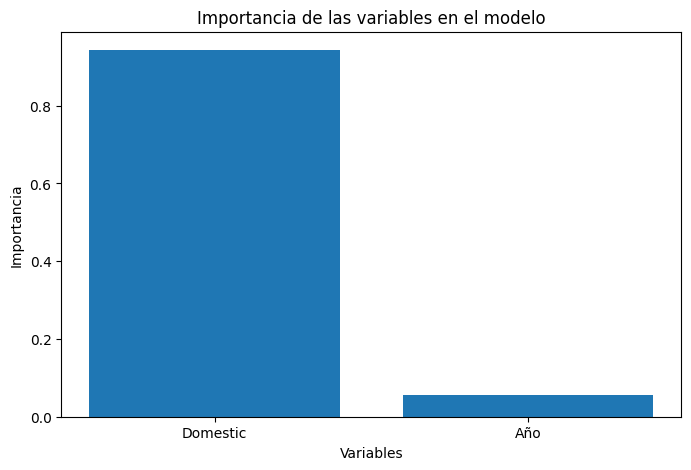

In [ ]:

# RESUMEN FINAL DE LOS MODELOS

comparacion = pd.DataFrame({
    "Modelo": ["Regresión lineal", "Random Forest optimizado"],
    "R2": [r2_inicial, r2_optimizado],
    "MAE": [mae_inicial, mae_optimizado]
})

print("COMPARACIÓN FINAL:")
display(comparacion)

# Calcular la reducción del error
reduccion_error = (
    (mae_inicial - mae_optimizado) / mae_inicial
) * 100

print(
    "\nReducción del error:",
    round(reduccion_error, 2),
    "%"
)

# IMPORTANCIA DE LAS VARIABLES
importancias = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": mejor_modelo.feature_importances_
})

importancias = importancias.sort_values(
    by="Importancia", ascending=False
)

print("\nIMPORTANCIA DE LAS VARIABLES:")
display(importancias)

# Crear gráfica
plt.figure(figsize=(8, 5))
plt.bar(
    importancias["Variable"],
    importancias["Importancia"]
)
plt.title("Importancia de las variables en el modelo")
plt.xlabel("Variables")
plt.ylabel("Importancia")
plt.show()
